# Lab 6: Data Aggregation (Retail Sales Analysis)
**Aim:** Aggregate retail sales by region and product category, bar charts, pie charts, and grouped bar chart.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

# 1. Create dataset
wine = load_wine(as_frame=True).frame
np.random.seed(42)
df = pd.DataFrame({
    'Transaction_Date': pd.date_range('2025-01-01', periods=len(wine)),
    'Region': np.random.choice(['North', 'South', 'East', 'West'], len(wine)),
    'Product_Category': wine['target'].map({0: 'Electronics', 1: 'Clothing', 2: 'Grocery'}),
    'Quantity_Sold': np.random.randint(1, 11, len(wine)),
    'Sales_Amount': np.random.uniform(500, 5000, len(wine)).round(2)
})
df.head()

,Transaction_Date,Region,Product_Category,Quantity_Sold,Sales_Amount
0,2025-01-01,East,Electronics,1,2761.87
1,2025-01-02,West,Electronics,3,3096.07
2,2025-01-03,North,Electronics,5,2716.33
3,2025-01-04,East,Electronics,3,1378.59
4,2025-01-05,East,Electronics,1,3751.03


Top-performing region: West Total: ₹148,374.57


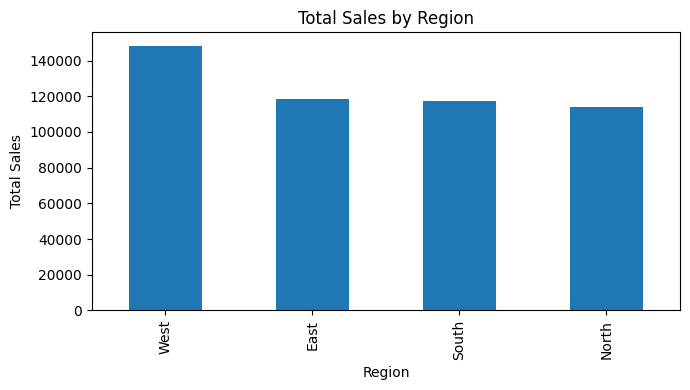

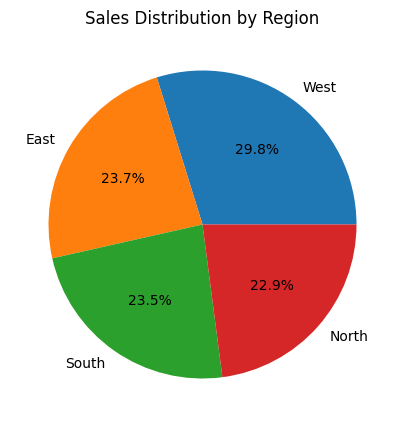

In [2]:
# 2. Regional Sales & Charts
reg_sales = df.groupby('Region')['Sales_Amount'].sum().sort_values(ascending=False)
print("Top-performing region:", reg_sales.idxmax(), f"Total: ₹{reg_sales.max():,.2f}")

plt.figure(figsize=(7, 4))
reg_sales.plot(kind='bar', title='Total Sales by Region', ylabel='Total Sales')
plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 5))
reg_sales.plot(kind='pie', autopct='%1.1f%%', title='Sales Distribution by Region')
plt.ylabel('')
plt.show()

Pivot Table:
 Product_Category  Clothing  Electronics   Grocery
Region                                           
East              28254.71     46271.05  43666.41
North             38584.45     28937.83  46686.97
South             59677.73     43968.69  13550.81
West              52347.03     60242.95  35784.59


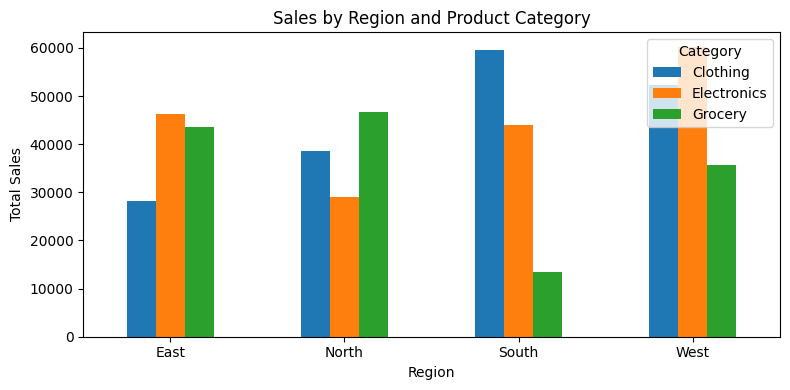

In [3]:
# 3. Pivot Table & Grouped Bar Chart
pivot = pd.pivot_table(df, values='Sales_Amount', index='Region', columns='Product_Category', aggfunc='sum', fill_value=0)
print("Pivot Table:\n", pivot)

pivot.plot(kind='bar', figsize=(8, 4), title='Sales by Region and Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.legend(title='Category')
plt.tight_layout()
plt.show()